# Modeling

1. Baseline every model on all features, scored with 5 fold CV on the training split.
2. Look at which features the trees and the logistic model lean on.
3. Re-run the same models on the top features only.

`X_test` is not touched here. Tuning and the final test score go in `06_evaluation_and_tuning`.

In [21]:
import sys, warnings
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

from utils.get_google_drive_data import load_csv_from_drive
from utils.google_drive_client import get_drive_client
from utils.utils import get_data_split
from sklearn.inspection import permutation_importance
from utils.preprocessing import drop_leaks, feature_names, make_pipeline

pd.set_option("display.width", 150)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
SEED = 42

In [22]:
service = get_drive_client()
df = load_csv_from_drive(service)

X_train, X_test, y_train, y_test = get_data_split(df)

# get_data_split leaves the five outcome columns in X, and they leak
X_train = drop_leaks(X_train)
X_test = drop_leaks(X_test)

print(f"train {X_train.shape}   test {X_test.shape}   base rate {y_train.mean():.3f}")
print("columns:", X_train.columns.tolist())

train (29375, 11)   test (12590, 11)   base rate 0.547
columns: ['project id', 'name', 'url', 'category', 'subcategory', 'location', 'goal', 'funded date', 'levels', 'reward levels', 'duration']


## 1. Baseline on all features

Same pipeline for every model. Everything that learns from the data sits inside it, so the CV
folds stay clean.

In [23]:
CV = StratifiedKFold(5, shuffle=True, random_state=SEED)
SCORING = ["roc_auc", "accuracy", "f1", "average_precision"]


def run_experiments(models, X, y, keep=None, label="", cv=CV):
    "Cross validate each model and return one row per model."
    rows = []
    for name, model in models.items():
        pipe = make_pipeline(model, keep=keep)
        cvres = cross_validate(pipe, X, y, cv=cv, scoring=SCORING, n_jobs=-1)
        row = {"model": name, "features": label}
        for s in SCORING:
            row[s] = cvres[f"test_{s}"].mean()
        row["auc_std"] = cvres["test_roc_auc"].std()
        row["fit_sec"] = cvres["fit_time"].mean()
        rows.append(row)
    return pd.DataFrame(rows).set_index("model").sort_values("roc_auc", ascending=False)


MODELS = {
    "dummy (majority)": DummyClassifier(strategy="prior"),
    "logistic": LogisticRegression(max_iter=2000, C=1.0),
    "knn (k=25)": KNeighborsClassifier(n_neighbors=25, n_jobs=-1),
    "decision tree": DecisionTreeClassifier(max_depth=8, min_samples_leaf=50, random_state=SEED),
    "random forest": RandomForestClassifier(
        n_estimators=400, min_samples_leaf=5, n_jobs=-1, random_state=SEED),
    "hist gradient boosting": HistGradientBoostingClassifier(
        max_iter=400, learning_rate=0.06, random_state=SEED),
}

exp_all = run_experiments(MODELS, X_train, y_train, label="all (35)")
exp_all.round(4)

,features,roc_auc,accuracy,f1,average_precision,auc_std,fit_sec
model,,,,,,,
hist gradient boosting,all (35),0.7682,0.7045,0.7464,0.7767,0.0060,3.6431
random forest,all (35),0.7656,0.7055,0.7480,0.7738,0.0064,7.0881
logistic,all (35),0.7648,0.7057,0.7426,0.7690,0.0047,3.0550
decision tree,all (35),0.7321,0.6805,0.7242,0.7320,0.0054,3.2742
knn (k=25),all (35),0.6977,0.6543,0.7196,0.6981,0.0077,3.1575
dummy (majority),all (35),0.5000,0.5473,0.7075,0.5473,0.0000,2.9322


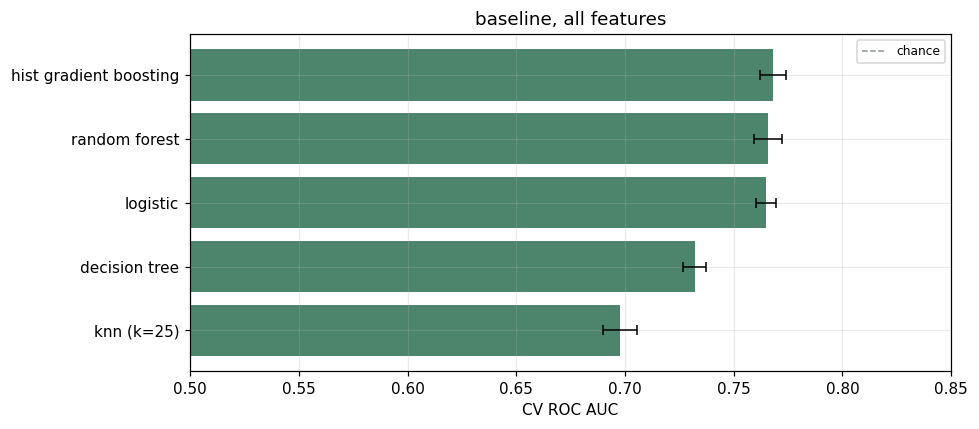

In [24]:
fig, ax = plt.subplots(figsize=(9, 4))
d = exp_all.drop(index="dummy (majority)").sort_values("roc_auc")
ax.barh(d.index, d["roc_auc"], xerr=d["auc_std"], color="#2c6f52", alpha=0.85,
        error_kw=dict(ecolor="k", capsize=3, lw=1))
ax.axvline(0.5, color="#8a9590", ls="--", lw=1, label="chance")
ax.set_xlim(0.5, 0.85); ax.set_xlabel("CV ROC AUC"); ax.legend(fontsize=8)
ax.set_title("baseline, all features")
plt.tight_layout()

## 2. Feature Importance/ Coefficients


In [25]:
rf = make_pipeline(RandomForestClassifier(
    n_estimators=400, min_samples_leaf=5, n_jobs=-1, random_state=SEED)).fit(X_train, y_train)
gb = make_pipeline(HistGradientBoostingClassifier(
    max_iter=400, learning_rate=0.06, random_state=SEED)).fit(X_train, y_train)
lr = make_pipeline(LogisticRegression(max_iter=2000)).fit(X_train, y_train)

names = feature_names(rf)
imp = pd.DataFrame({
    "random forest": rf.named_steps["model"].feature_importances_,
    "logistic |coef|": np.abs(lr.named_steps["model"].coef_[0]),
}, index=names)
imp["logistic coef"] = lr.named_steps["model"].coef_[0]

# rank them so the two scales can be compared
imp["rf rank"] = imp["random forest"].rank(ascending=False)
imp["lr rank"] = imp["logistic |coef|"].rank(ascending=False)
imp["mean rank"] = imp[["rf rank", "lr rank"]].mean(axis=1)
imp.sort_values("mean rank").head(20).round(4)

,random forest,logistic |coef|,logistic coef,rf rank,lr rank,mean rank
goal_per_tier,0.0938,1.9527,-1.9527,1.0,3.0,2.0
te_state,0.0554,4.1864,4.1864,4.0,1.0,2.5
te_subcategory,0.0731,3.9550,3.9550,3.0,2.0,2.5
backers_needed,0.0853,0.8615,0.8615,2.0,4.0,3.0
goal_vs_subcat,0.0460,0.5243,-0.5243,8.0,7.0,7.5
te_category,0.0472,0.4368,0.4368,7.0,10.0,8.5
goal_per_day,0.0476,0.4236,-0.4236,6.0,11.0,8.5
entry_vs_goal,0.0370,0.7819,-0.7819,13.0,5.0,9.0
log_goal,0.0420,0.4803,0.4803,11.0,8.0,9.5
duration,0.0440,0.3633,-0.3633,9.0,12.0,10.5


In [26]:
# impurity importance is biased, permutation importance is better but more computationally expensive
# Link article for source
perm = permutation_importance(gb, X_train, y_train, scoring="roc_auc",
                              n_repeats=3, random_state=SEED, n_jobs=-1)
pd.Series(perm.importances_mean, index=X_train.columns).sort_values(ascending=False).round(4)


goal             0.1617
reward levels    0.1275
duration         0.0335
name             0.0163
funded date      0.0097
subcategory      0.0049
url              0.0014
category         0.0009
location         0.0008
project id       0.0000
levels           0.0000
dtype: float64

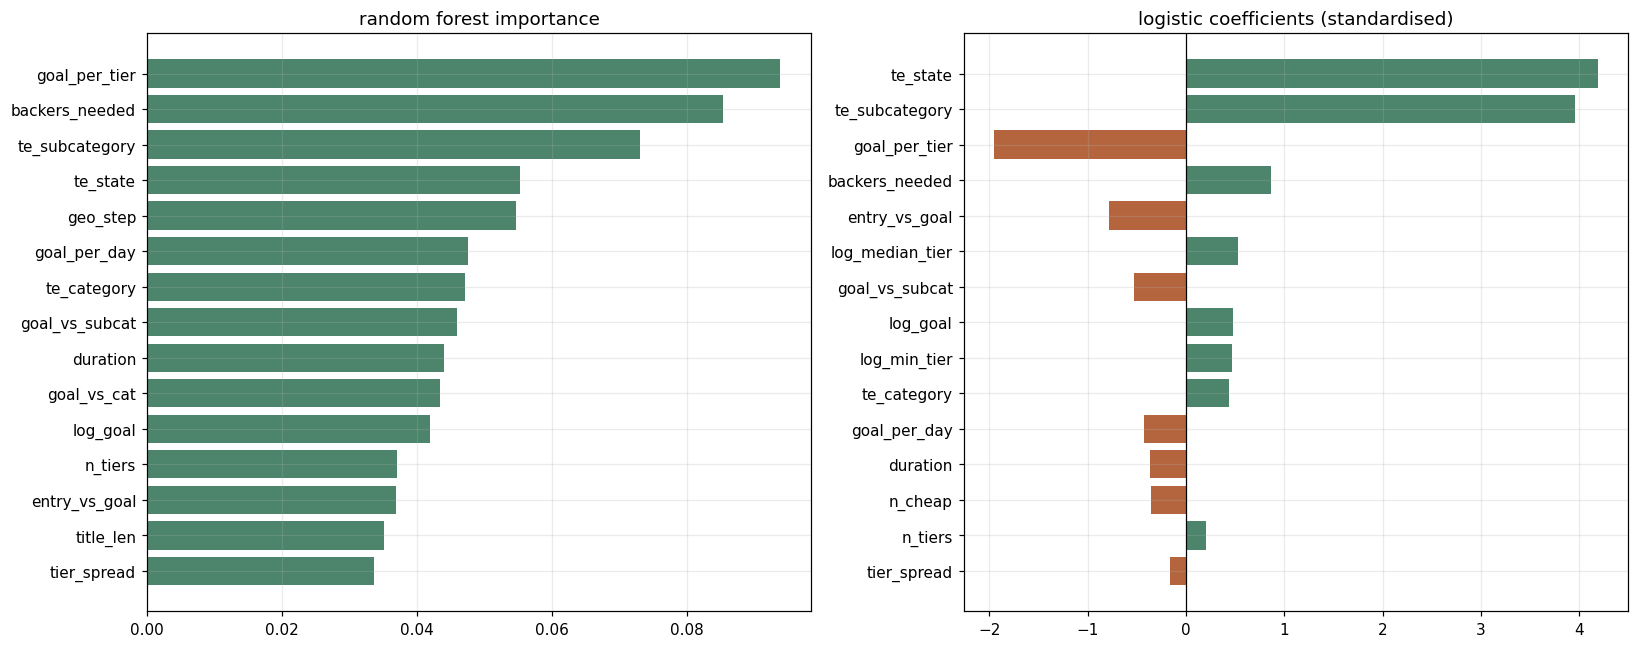

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
top_rf = imp["random forest"].sort_values().tail(15)
axes[0].barh(top_rf.index, top_rf.values, color="#2c6f52", alpha=0.85)
axes[0].set_title("random forest importance")

top_lr = imp["logistic coef"].reindex(imp["logistic |coef|"].sort_values().tail(15).index)
axes[1].barh(top_lr.index, top_lr.values,
             color=["#a84a1c" if v < 0 else "#2c6f52" for v in top_lr.values], alpha=0.85)
axes[1].axvline(0, color="k", lw=0.8)
axes[1].set_title("logistic coefficients (standardised)")
plt.tight_layout()

The two rankings mostly agree at the top. Goal and its variants come first, then the encoded
subcategory, then the reward ladder. The signs make sense: bigger ask and longer duration push
down, more tiers and a cheap entry push up.

In [28]:
TOP_K = 12
top_features = imp.sort_values("mean rank").head(TOP_K).index.tolist()
print(f"top {TOP_K} by mean rank:")
for f in top_features:
    print("  ", f)

top 12 by mean rank:
   goal_per_tier
   te_state
   te_subcategory
   backers_needed
   goal_vs_subcat
   te_category
   goal_per_day
   entry_vs_goal
   log_goal
   duration
   log_median_tier
   n_tiers


## 3. Baseline models with top features only

In [29]:
exp_top = run_experiments(MODELS, X_train, y_train, keep=top_features, label=f"top {TOP_K}")
exp_top.round(4)

,features,roc_auc,accuracy,f1,average_precision,auc_std,fit_sec
model,,,,,,,
hist gradient boosting,top 12,0.7625,0.7021,0.7459,0.7701,0.0059,31.0934
random forest,top 12,0.7589,0.7012,0.7430,0.7659,0.0054,13.6316
logistic,top 12,0.7556,0.6965,0.7356,0.7591,0.0043,2.9731
decision tree,top 12,0.7343,0.6833,0.7286,0.7354,0.0035,3.0239
knn (k=25),top 12,0.7271,0.6801,0.7305,0.7212,0.0054,2.9470
dummy (majority),top 12,0.5000,0.5473,0.7075,0.5473,0.0000,2.9296


In [30]:
compare = pd.concat([
    exp_all[["roc_auc", "accuracy", "auc_std"]].add_suffix(" (all)"),
    exp_top[["roc_auc", "accuracy", "auc_std"]].add_suffix(f" (top {TOP_K})"),
], axis=1)
compare["auc delta"] = compare[f"roc_auc (top {TOP_K})"] - compare["roc_auc (all)"]
compare.sort_values(f"roc_auc (top {TOP_K})", ascending=False).round(4)

,roc_auc (all),accuracy (all),auc_std (all),roc_auc (top 12),accuracy (top 12),auc_std (top 12),auc delta
model,,,,,,,
hist gradient boosting,0.7682,0.7045,0.0060,0.7625,0.7021,0.0059,-0.0057
random forest,0.7656,0.7055,0.0064,0.7589,0.7012,0.0054,-0.0067
logistic,0.7648,0.7057,0.0047,0.7556,0.6965,0.0043,-0.0092
decision tree,0.7321,0.6805,0.0054,0.7343,0.6833,0.0035,0.0023
knn (k=25),0.6977,0.6543,0.0077,0.7271,0.6801,0.0054,0.0293
dummy (majority),0.5000,0.5473,0.0000,0.5000,0.5473,0.0000,0.0000


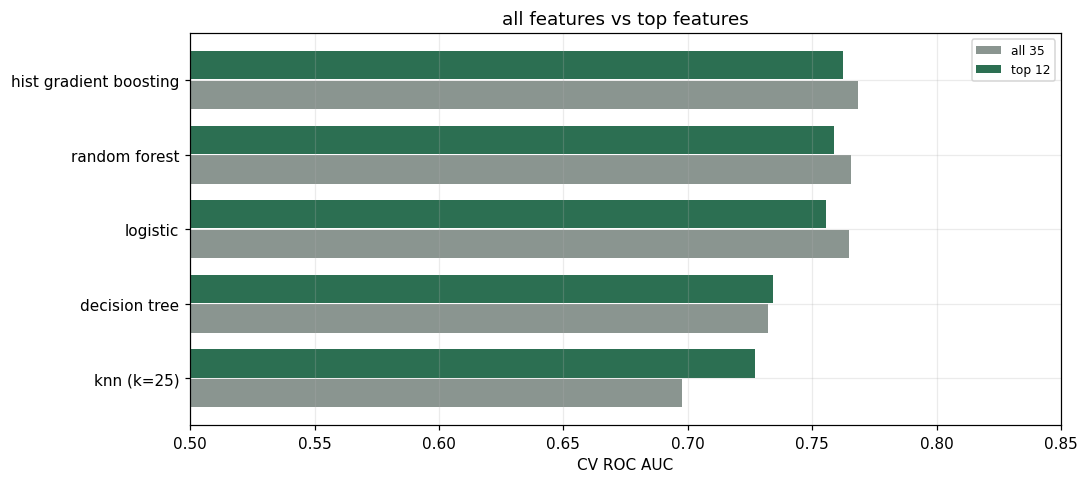

In [31]:
fig, ax = plt.subplots(figsize=(10, 4.5))
d = compare.drop(index="dummy (majority)").sort_values("roc_auc (all)")
y_pos = np.arange(len(d))
ax.barh(y_pos - 0.2, d["roc_auc (all)"], height=0.38, color="#8a9590", label="all 35")
ax.barh(y_pos + 0.2, d[f"roc_auc (top {TOP_K})"], height=0.38, color="#2c6f52",
        label=f"top {TOP_K}")
ax.set_yticks(y_pos); ax.set_yticklabels(d.index)
ax.set_xlim(0.5, 0.85); ax.set_xlabel("CV ROC AUC"); ax.legend(fontsize=8)
ax.set_title("all features vs top features")
plt.tight_layout()

## Summary

**Baseline.** Boosting 0.767, random forest 0.765, logistic 0.765. Those three are within a
standard deviation of each other, so maybe further finetunning or feature engineering could help choose a winner. Decision tree 0.729 and kNN 0.697 are behind.

**Importances.** Random forest and logistic agree on the top five: `goal_per_tier`,
`te_subcategory`, `te_state`, `backers_needed`, `goal_vs_subcat`.  


